<div dir="rtl">

# 02 · עיבוד מקדים ומודלי סיווג

**הסדר (כדי למנוע Data Leakage, שיעור 1):**
1. לפצל ל־train/test **לפני הכול**, עם `stratify`.
2. כל העיבוד (One-hot, Scaling, Resampling) בתוך `Pipeline`, כך שהוא לומד רק מה־train.
3. להשוות מודלים ושיטות איזון ב־Cross-validation על ה־train בלבד (שיעור 2: Resampling בתוך כל fold).
4. רק בסוף: הערכה אחת על ה־test.

**מאיזה שיעור כל דבר:**
| מה | שיעור |
|---|---|
| Confusion matrix, Precision, Recall, F1, Macro F1, למה לא Accuracy | 1 |
| Random Oversampling, SMOTE, Tomek Links, NearMiss, SMOTEENN, Class weights | 1 |
| `stratify`, Data Leakage, Resampling רק על ה־train | 1 |
| Resampling בתוך כל fold עם Pipeline של imblearn, הזזת סף, PR-AUC | 2 (בוחן החזרה) |
| MLP, Scaling לטווח 0–1, Early stopping, XGBoost לדאטה טבלאי | 2 |
| רגרסיה לוגיסטית, עץ החלטה, Random Forest, KNN | מודלים מהסמסטר הקודם, שהמרצה הזכיר בשיעורים 1–2 |

> כל תא קוד במחברת נכתב בעזרת Claude, ולכן מסומן `### CODE BY CLAUDE ###` לפי הנחיות המרצה.

</div>

In [1]:
### CODE BY CLAUDE ###
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # כדי שאפשר יהיה לייבא את src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import (load_raw, add_features, get_xy, build_preprocessor, FIGURES,
                      RANDOM_STATE, TARGET, SEVERITY_NAMES, CATEGORICAL, NUMERIC, BINARY)

sns.set_theme(style="whitegrid")
FIGURES.mkdir(exist_ok=True)
SEV_ORDER = ["קטלנית", "קשה", "קלה"]
SEV_COLORS = ["#a3262c", "#e08a2c", "#7a8aa0"]

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (f1_score, recall_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer)
from sklearn.preprocessing import label_binarize
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import TomekLinks, NearMiss
from imblearn.combine import SMOTEENN
from xgboost import XGBClassifier

# שמות בעברית לטבלאות התוצאות
COLS_HE = {"model": "מודל", "balance": "איזון", "f1_macro": "F1-macro", "recall_fatal": "Recall קטלנית",
           "pr_auc": "PR-AUC", "accuracy": "Accuracy"}
BALANCE_HE = {"none": "בלי טיפול", "class_weight": "class_weight", "smote": "SMOTE"}
####

<div dir="rtl">

## 1. פיצול train/test (שיעור 1: stratify)
בלי 1,235 התאונות שאין בהן פרטי דרך (ראו `01_eda`, סעיף 6), ובלי 22 תאונות שאין להן קואורדינטות.
80/20, עם `stratify=y`: בשני החלקים יהיה אותו אחוז של קטלניות (כ־5.7%).

</div>

In [2]:
### CODE BY CLAUDE ###
X, y = get_xy(load_raw())
# מחלקות כ־0/1/2 (‏XGBoost דורש תוויות שמתחילות ב־0): ‏0 = קטלנית, 1 = קשה, 2 = קלה
y = y - 1
CLASS_NAMES = SEV_ORDER

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, " test:", X_test.shape)
print(pd.DataFrame({"% ב־train": y_train.value_counts(normalize=True).sort_index().mul(100).round(1),
                    "% ב־test": y_test.value_counts(normalize=True).sort_index().mul(100).round(1)},
                   ).set_axis(CLASS_NAMES))
####

train: (5648, 33)  test: (1412, 33)
        % ב־train  % ב־test
קטלנית        5.6       5.6
קשה          21.2      21.2
קלה          73.2      73.2


<div dir="rtl">

## 2. העיבוד המקדים
- **קטגוריות (28):** One-hot. כל קוד הופך לעמודה של 0/1, כי הקודים הם שמות של קטגוריות ולא כמויות.
- **מספריות (X, Y):** Scaling לטווח 0–1 עם `MinMaxScaler`, כמו בשיעור 2. ה־fit רק על ה־train (זה קורה לבד בתוך ה־Pipeline).
- **דגלים (3):** כבר 0/1, עוברים כמו שהם.

</div>

In [3]:
### CODE BY CLAUDE ###
prep = build_preprocessor().fit(X_train)
print("מספר פיצ'רים אחרי One-hot:", prep.transform(X_train.head()).shape[1])
####

מספר פיצ'רים אחרי One-hot: 236


<div dir="rtl">

## 3. המדדים (שיעורים 1–2)
- **Macro F1 (המדד הראשי, שיעור 1):** ממוצע של F1 בכל מחלקה. כך הקטלנית שוקלת כמו האחרות, למרות שהיא 5% מהדאטה.
- **Recall של קטלנית (שיעור 1):** כמה מהתאונות הקטלניות המודל תפס.
- **PR-AUC (שיעור 2):** כמה טוב המודל מפריד בין המחלקות, בלי תלות בסף. מתאים לדאטה לא מאוזן.
- Accuracy מוצג רק להשוואה. בשיעור 1 ראינו שבדאטה לא מאוזן הוא מטעה.

</div>

In [4]:
### CODE BY CLAUDE ###
def pr_auc_macro(y_true, proba):
    y_bin = label_binarize(y_true, classes=[0, 1, 2])
    return average_precision_score(y_bin, proba, average="macro")

SCORING = {
    "f1_macro": "f1_macro",
    "recall_fatal": make_scorer(recall_score, labels=[0], average="macro"),
    "pr_auc": make_scorer(pr_auc_macro, response_method="predict_proba"),
    "accuracy": "accuracy",
}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
####

<div dir="rtl">

## 4. ניסוי 1: 6 מודלים × 3 שיטות איזון
- **בלי טיפול.**
- **class_weight (שיעור 1):** טעות על מחלקה קטנה "עולה" יותר (`class_weight="balanced"`, וב־XGBoost אותו דבר דרך `sample_weight`). ל־MLP ול־KNN אין אפשרות כזו.
- **SMOTE (שיעור 1):** **בתוך** הפייפליין של imblearn, כך שבכל fold הוא רץ רק על חלק האימון (שיעור 2).
- ב־MLP: ‏`early_stopping=True` (שיעור 2).

</div>

In [5]:
### CODE BY CLAUDE ###
def make_models(balance):
    cw = "balanced" if balance == "class_weight" else None
    models = {
        "LogisticRegression": LogisticRegression(max_iter=2000, class_weight=cw, random_state=RANDOM_STATE),
        "DecisionTree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight=cw, random_state=RANDOM_STATE),
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight=cw, n_jobs=-1, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                 eval_metric="mlogloss", n_jobs=-1, random_state=RANDOM_STATE),
    }
    if balance != "class_weight":   # לשני המודלים האלה אין class_weight
        models["MLP"] = MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                      max_iter=300, random_state=RANDOM_STATE)
        models["KNN"] = KNeighborsClassifier(n_neighbors=15)
    return models

def make_pipeline(model, sampler=None):
    steps = [("prep", build_preprocessor())]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("clf", model))
    return Pipeline(steps)

rows = []
for balance in ["none", "class_weight", "smote"]:
    for name, model in make_models(balance).items():
        params = {}
        if balance == "class_weight" and name == "XGBoost":
            params = {"clf__sample_weight": compute_sample_weight("balanced", y_train)}
        sampler = SMOTE(random_state=RANDOM_STATE) if balance == "smote" else None
        res = cross_validate(make_pipeline(model, sampler), X_train, y_train, cv=CV,
                             scoring=SCORING, params=params, n_jobs=1)
        rows.append({"model": name, "balance": BALANCE_HE[balance],
                     **{m: res[f"test_{m}"].mean() for m in SCORING}})
        print(f"{name:20s} {BALANCE_HE[balance]:13s} F1-macro={rows[-1]['f1_macro']:.3f}  Recall קטלנית={rows[-1]['recall_fatal']:.3f}")

results = pd.DataFrame(rows).round(3).sort_values("f1_macro", ascending=False)
results.rename(columns=COLS_HE).to_csv(FIGURES / "experiment1_results.csv", index=False, encoding="utf-8-sig")
results.rename(columns=COLS_HE)
####

LogisticRegression   בלי טיפול     F1-macro=0.417  Recall קטלנית=0.120


DecisionTree         בלי טיפול     F1-macro=0.363  Recall קטלנית=0.025


RandomForest         בלי טיפול     F1-macro=0.320  Recall קטלנית=0.006


XGBoost              בלי טיפול     F1-macro=0.390  Recall קטלנית=0.079


MLP                  בלי טיפול     F1-macro=0.316  Recall קטלנית=0.000


KNN                  בלי טיפול     F1-macro=0.328  Recall קטלנית=0.016


... (7 outputs left out)

XGBoost              SMOTE         F1-macro=0.355  Recall קטלנית=0.060


MLP                  SMOTE         F1-macro=0.404  Recall קטלנית=0.146


KNN                  SMOTE         F1-macro=0.290  Recall קטלנית=0.471


,מודל,איזון,F1-macro,Recall קטלנית,PR-AUC,Accuracy
8,RandomForest,class_weight,0.447,0.354,0.448,0.624
9,XGBoost,class_weight,0.437,0.408,0.446,0.602
6,LogisticRegression,class_weight,0.435,0.538,0.443,0.578
10,LogisticRegression,SMOTE,0.425,0.522,0.431,0.564
11,DecisionTree,SMOTE,0.424,0.266,0.411,0.627
12,RandomForest,SMOTE,0.421,0.120,0.451,0.726
0,LogisticRegression,בלי טיפול,0.417,0.120,0.473,0.734
14,MLP,SMOTE,0.404,0.146,0.405,0.649
3,XGBoost,בלי טיפול,0.390,0.079,0.471,0.735
7,DecisionTree,class_weight,0.376,0.566,0.406,0.461


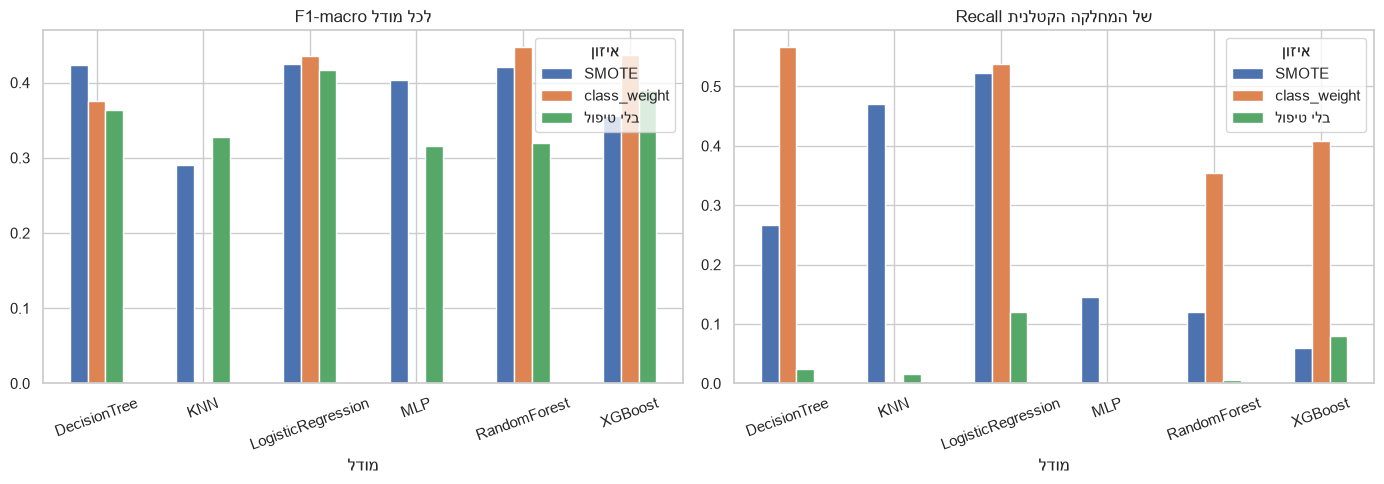

In [6]:
### CODE BY CLAUDE ###
pivot = results.pivot(index="model", columns="balance", values="f1_macro")
pivot_r = results.pivot(index="model", columns="balance", values="recall_fatal")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pivot.plot.bar(ax=axes[0], rot=20); axes[0].set_title("F1-macro לכל מודל")
pivot_r.plot.bar(ax=axes[1], rot=20); axes[1].set_title("Recall של המחלקה הקטלנית")
for ax in axes:
    ax.set_xlabel("מודל"); ax.legend(title="איזון")
plt.tight_layout(); plt.savefig(FIGURES / "09_experiment1.png", dpi=150); plt.show()
####

<div dir="rtl">

**מה לשים לב (לפגישה):**
- בלי טיפול באיזון, ה־Recall של הקטלנית קרוב ל־0: המודלים פשוט לא מנבאים "קטלנית".
- class_weight ו־SMOTE מעלים מאוד את ה־Recall של הקטלנית, ובדרך כלל מורידים את ה־Accuracy. זה ה־trade-off משיעור 1.

</div>

<div dir="rtl">

## 5. ניסוי 2: כל שיטות ה־Resampling משיעור 1, על המודל המוביל
לוקחים את המודל עם ה־F1-macro הכי גבוה בניסוי 1, ומשווים עליו את כל השיטות שהוצגו בשיעור 1:
Random Oversampling, ‏SMOTE, ‏Tomek Links, ‏NearMiss, ‏SMOTEENN, ו־class_weight. הכול בתוך הפייפליין, כך שכל שיטה רצה רק על ה־train של כל fold.

</div>

In [7]:
### CODE BY CLAUDE ###
best_model_name = results.iloc[0]["model"]
print("המודל המוביל מניסוי 1:", best_model_name)

samplers = {
    "בלי טיפול": None,
    "Random Oversampling": RandomOverSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
    "Tomek Links": TomekLinks(),
    "NearMiss": NearMiss(version=1),
    "SMOTEENN": SMOTEENN(random_state=RANDOM_STATE),
}
rows2 = []
for label, sampler in samplers.items():
    model = make_models("none")[best_model_name]
    res = cross_validate(make_pipeline(model, sampler), X_train, y_train, cv=CV, scoring=SCORING, n_jobs=1)
    rows2.append({"איזון": label, **{COLS_HE[m]: res[f"test_{m}"].mean() for m in SCORING}})
    print(f"{label:20s} F1-macro={rows2[-1]['F1-macro']:.3f}")
# class_weight מניסוי 1, לאותו מודל
cw_row = results[(results["model"] == best_model_name) & (results["balance"] == "class_weight")].iloc[0]
rows2.append({"איזון": "class_weight", **{COLS_HE[m]: cw_row[m] for m in SCORING}})
resampling = pd.DataFrame(rows2).round(3).sort_values("F1-macro", ascending=False)
resampling.to_csv(FIGURES / "experiment2_resampling.csv", index=False, encoding="utf-8-sig")
resampling
####

המודל המוביל מניסוי 1: RandomForest


בלי טיפול            F1-macro=0.320


Random Oversampling  F1-macro=0.460


SMOTE                F1-macro=0.421


Tomek Links          F1-macro=0.314


NearMiss             F1-macro=0.261


SMOTEENN             F1-macro=0.356


,איזון,F1-macro,Recall קטלנית,PR-AUC,Accuracy
1,Random Oversampling,0.460,0.193,0.452,0.698
6,class_weight,0.447,0.354,0.448,0.624
2,SMOTE,0.421,0.120,0.451,0.726
5,SMOTEENN,0.356,0.225,0.427,0.418
0,בלי טיפול,0.320,0.006,0.469,0.735
3,Tomek Links,0.314,0.013,0.467,0.733
4,NearMiss,0.261,0.674,0.377,0.293


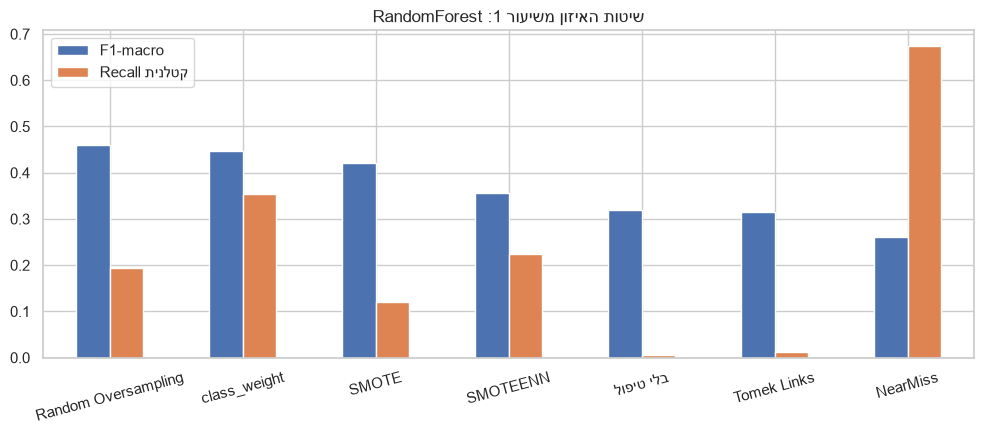

In [8]:
### CODE BY CLAUDE ###
ax = resampling.set_index("איזון")[["F1-macro", "Recall קטלנית"]].plot.bar(figsize=(10, 4.5), rot=15)
ax.set_title(f"שיטות האיזון משיעור 1: {best_model_name}")
ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIGURES / "10_resampling_methods.png", dpi=150); plt.show()
####

<div dir="rtl">

**מה לשים לב:** NearMiss זורק הרבה דוגמאות מהרוב, ולכן ה־Recall של קטלנית עולה אבל הדיוק על שאר המחלקות נפגע.
Tomek Links מוחק רק מעט נקודות "גבול", ולכן הוא קרוב ל"בלי טיפול". זה בדיוק מה שראינו בשיעור 1.

</div>

<div dir="rtl">

## 6. הערכה סופית על ה־test
בוחרים את השילוב (מודל + שיטת איזון) עם ה־F1-macro הכי גבוה ב־CV, מאמנים אותו על כל ה־train, ובודקים **פעם אחת** על ה־test.

</div>

In [9]:
### CODE BY CLAUDE ###
# הבחירה לפי ה־CV על ה־train, אף פעם לא לפי ה־test
best_balance = resampling.iloc[0]["איזון"]
if best_balance == "class_weight":
    final = make_pipeline(make_models("class_weight")[best_model_name])
    fit_params = {"clf__sample_weight": compute_sample_weight("balanced", y_train)} if best_model_name == "XGBoost" else {}
else:
    final = make_pipeline(make_models("none")[best_model_name], samplers[best_balance])
    fit_params = {}
final.fit(X_train, y_train, **fit_params)
print("המודל הסופי:", best_model_name, "+", best_balance)

proba = final.predict_proba(X_test)
pred = proba.argmax(axis=1)
test_results = pd.DataFrame([{"מודל": best_model_name, "איזון": best_balance,
                              "F1-macro": f1_score(y_test, pred, average="macro"),
                              "Recall קטלנית": recall_score(y_test, pred, labels=[0], average="macro"),
                              "PR-AUC": pr_auc_macro(y_test, proba),
                              "Accuracy": (pred == y_test).mean()}]).round(3)
test_results.to_csv(FIGURES / "test_results.csv", index=False, encoding="utf-8-sig")
print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=3))
test_results
####

המודל הסופי: RandomForest + Random Oversampling
              precision    recall  f1-score   support

      קטלנית      0.204     0.139     0.165        79
         קשה      0.324     0.304     0.314       299
         קלה      0.805     0.838     0.821      1034

    accuracy                          0.686      1412
   macro avg      0.444     0.427     0.434      1412
weighted avg      0.669     0.686     0.677      1412



,מודל,איזון,F1-macro,Recall קטלנית,PR-AUC,Accuracy
0,RandomForest,Random Oversampling,0.434,0.139,0.446,0.686


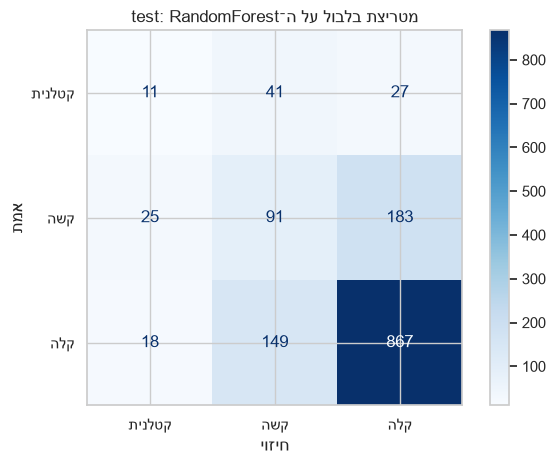

In [10]:
### CODE BY CLAUDE ###
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASS_NAMES).plot(cmap="Blues")
plt.title(f"מטריצת בלבול על ה־test: {best_model_name}")
plt.xlabel("חיזוי"); plt.ylabel("אמת")
plt.tight_layout(); plt.savefig(FIGURES / "11_confusion_matrix.png", dpi=150); plt.show()
####

<div dir="rtl">

## 7. הזזת סף לקטלנית (שיעור 2)
המודל נותן הסתברות לכל מחלקה. ברירת המחדל: לבחור את הגבוהה ביותר.
כאן מכריזים "קטלנית" כבר כשההסתברות שלה עוברת סף נמוך יותר, ובודקים מה קורה ל־Recall ול־Precision שלה.
⚠️ בפרויקט עצמו את הסף בוחרים על validation (או CV) ולא על ה־test. כאן זה רק להמחשה של ה־trade-off.

</div>

In [11]:
### CODE BY CLAUDE ###
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1]:
    pred_t = proba.argmax(axis=1)
    pred_t[proba[:, 0] >= t] = 0
    rows.append({"סף": t,
                 "Recall קטלנית": recall_score(y_test, pred_t, labels=[0], average="macro"),
                 "Precision קטלנית": ((pred_t == 0) & (y_test == 0)).sum() / max((pred_t == 0).sum(), 1),
                 "F1-macro": f1_score(y_test, pred_t, average="macro")})
pd.DataFrame(rows).round(3)
####

,סף,Recall קטלנית,Precision קטלנית,F1-macro
0,0.50,0.139,0.204,0.434
1,0.40,0.152,0.211,0.435
2,0.30,0.266,0.196,0.441
3,0.20,0.456,0.152,0.415
4,0.15,0.544,0.125,0.388
5,0.10,0.747,0.104,0.333


<div dir="rtl">

## 8. ניתוח שגיאות: על אילו תאונות קטלניות המודל טעה?
(ניתוח שגיאות נדרש במסמך הפרויקט.) משווים את הקטלניות שהמודל **פספס** לאלה שהוא **תפס**, בכמה פיצ'רים מרכזיים.

</div>

In [12]:
### CODE BY CLAUDE ###
fatal_test = X_test[y_test == 0].copy()
fatal_test["נתפסה"] = pred[y_test.values == 0] == 0
print(f"תאונות קטלניות ב־test: {len(fatal_test)}, המודל תפס: {fatal_test['נתפסה'].sum()}")
for col in ["SUG_DEREH", "YOM_LAYLA", "SUG_TEUNA", "HAS_ROAD_NUMBER"]:
    print(f"\n{col}: אחוז מהתאונות הקטלניות בכל קוד, נתפסו מול פוספסו")
    print(pd.crosstab(fatal_test[col], fatal_test["נתפסה"], normalize="columns").mul(100).round(0)
          .rename(columns={True: "נתפסו", False: "פוספסו"}))
####

תאונות קטלניות ב־test: 79, המודל תפס: 11

SUG_DEREH: אחוז מהתאונות הקטלניות בכל קוד, נתפסו מול פוספסו
נתפסה      פוספסו  נתפסו
SUG_DEREH               
1            18.0    0.0
2            31.0    0.0
3             9.0    9.0
4            43.0   91.0

YOM_LAYLA: אחוז מהתאונות הקטלניות בכל קוד, נתפסו מול פוספסו
נתפסה      פוספסו  נתפסו
YOM_LAYLA               
1            57.0   18.0
5            43.0   82.0

SUG_TEUNA: אחוז מהתאונות הקטלניות בכל קוד, נתפסו מול פוספסו
נתפסה      פוספסו  נתפסו
SUG_TEUNA               
1            31.0   18.0
2            15.0    9.0
3            15.0   18.0
4            10.0    0.0
5             4.0   18.0
7             1.0    0.0
8             7.0    9.0
9             1.0    9.0
10            6.0    0.0
11            7.0    0.0
15            1.0    9.0
17            0.0    9.0

HAS_ROAD_NUMBER: אחוז מהתאונות הקטלניות בכל קוד, נתפסו מול פוספסו
נתפסה            פוספסו  נתפסו
HAS_ROAD_NUMBER               
0                  49.0    0.0
1               

<div dir="rtl">

## 9. ניסוי 3: בעיה בינארית, חמורה (קטלנית + קשה) מול קלה
שאלה: האם קל יותר להבדיל בין "חמורה" ל"קלה", מאשר להפריד גם בין קטלנית לקשה?

</div>

In [13]:
### CODE BY CLAUDE ###
yb_train = (y_train <= 1).astype(int)   # 1 = קטלנית או קשה
bin_rows = []
for name in ["LogisticRegression", "RandomForest", "XGBoost"]:
    model = make_models("class_weight")[name]
    fit_params = {"clf__sample_weight": compute_sample_weight("balanced", yb_train)} if name == "XGBoost" else {}
    res = cross_validate(make_pipeline(model), X_train, yb_train, cv=CV, params=fit_params,
                         scoring={"f1_macro": "f1_macro", "recall_severe": "recall", "pr_auc": "average_precision"})
    bin_rows.append({"מודל": name, "F1-macro": res["test_f1_macro"].mean(),
                     "Recall חמורה": res["test_recall_severe"].mean(), "PR-AUC": res["test_pr_auc"].mean()})
pd.DataFrame(bin_rows).round(3)
####

,מודל,F1-macro,Recall חמורה,PR-AUC
0,LogisticRegression,0.641,0.610,0.504
1,RandomForest,0.644,0.563,0.498
2,XGBoost,0.643,0.595,0.494


<div dir="rtl">

## 10. ניסוי 4: מה קורה אם משאירים את 1,235 התאונות בלי פרטי דרך? (שיעור 1: Data Leakage)
ב־EDA (סעיף 6) ראינו ש־77% מהן "קשות". אם משאירים אותן, המודל לומד את הארטיפקט, והציון "מתנפח".

</div>

In [14]:
### CODE BY CLAUDE ###
X_all, y_all = get_xy(load_raw(), drop_missing_details=False)
y_all = y_all - 1
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
art_rows = []
for label, (Xt, yt) in {"בלי השורות האלה (הניסוי הראשי)": (X_train, y_train),
                        "עם השורות האלה": (Xa_train, ya_train)}.items():
    pipe = make_pipeline(make_models("class_weight")["XGBoost"])
    res = cross_validate(pipe, Xt, yt, cv=CV, scoring=SCORING,
                         params={"clf__sample_weight": compute_sample_weight("balanced", yt)})
    art_rows.append({"הדאטה": label, "שורות": len(Xt),
                     **{COLS_HE[m]: res[f"test_{m}"].mean() for m in SCORING}})
pd.DataFrame(art_rows).round(3)
####

,הדאטה,שורות,F1-macro,Recall קטלנית,PR-AUC,Accuracy
0,בלי השורות האלה (הניסוי הראשי),5648,0.437,0.408,0.446,0.602
1,עם השורות האלה,6634,0.528,0.520,0.567,0.668


<div dir="rtl">

**מה לראות:** עם השורות האלה הציון גבוה יותר, בעיקר כי קל לזהות "קשה" לפי פרטים חסרים. זה לא שיפור אמיתי,
ולכן הניסוי הראשי בלעדיהן. בדו"ח זה ממצא טוב לסעיף ניתוח השגיאות / איכות הדאטה.

</div>

<div dir="rtl">

## סיכום ושאלות לפגישה
1. איזה מודל ניצח, ולמה? (בשיעור 2 המרצה אמר ש־XGBoost / עצים לרוב טובים יותר מרשת נוירונים בדאטה טבלאי. זה מה שקרה?)
2. איזו שיטת איזון עבדה הכי טוב, ומה המחיר ב־Accuracy?
3. איזה סף הייתם בוחרים לקטלנית, ולמה? (מה חשוב יותר: לפספס תאונה קטלנית, או התראת שווא?)
4. בהגנה ישנו פרמטרים: נסו לשנות `max_depth`, `n_neighbors` של KNN או `k_neighbors` של SMOTE, ולחזות מה יקרה לפני שמריצים.

</div>